In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#from scipy.integrate import solve_ivp
#from numba import jit

In [2]:
def ssa_hyperbolic(x0,tau):
    x=[x0]               #plasmid count count 
    t_x=[0]              #reaction time 
    while t_x[-1]<tau:
        a=(k_tr*x[-1])/(1+K*x[-1]/(s0*n))**n
        epsilon=np.random.uniform(0,1,1)
        t0=(np.log(1/epsilon))/a
        t_x=np.append(t_x,[t_x[-1]+t0])
        x=np.append(x,[x[-1]+1])
    return x[:-1],t_x[:-1]

def single_hyperbolic(x0,gen,tau,cluster):
    x=[x0]
    t=np.array([0])
    div_time=np.zeros(gen)
    for i in range(gen):
        if x0>0:
            xx,tt=ssa_hyperbolic(x0,tau)
            x=np.append(x,xx)
            t=np.append(t,t[-1]+tt)
            if cluster==False:
                x0=np.random.binomial(xx[-1],0.5)
            else:
                c_num =np.random.choice(np.arange(5),1,p=np.array([.04,.18,.48,.24,.06]))[0]
                if c_num == 0:
                    x0=np.random.binomial(xx[-1],0.5)
                else:
                    x0=0
                    c_size = np.random.multinomial(xx[-1], [1/c_num]*c_num, size=1)[0]
                    for k in range(len(c_size)):
                        dummy = np.random.uniform(0,1,1)
                        if dummy<0.5:
                            x0+=c_size[k]
                    #print('x0',x0)
                #print('c_num',c_num)
            div_time[i]=t[-1]
            #print('############# divide ################')
    return x,t#,div_time

def plot_stairs(x,t):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        plt.plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            plt.vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            plt.vlines(t[i+1],x[i],x[i+1],color='k')
    plt.ylim([0,max(x)+1])
    plt.xlim([0,gen*tau])
    plt.xlabel('time')
    plt.ylabel('Plasmid copy number')
    return None

def plot_stairs_multiple(x,t,k):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        axes[k].plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='k')
    axes[k].set_ylim([0,100])
    axes[k].set_xlim([0,gen*tau])
    axes[k].set_xlabel('time')
    axes[k].hlines(41,0,gen*tau,color='grey')
    if k>0:
        axes[k].set_yticklabels([])
    return None

In [3]:
tau = 60
k_tr = 2.73
K = 9.007936508
s0 = 13.58595
n = 2.5
gen = 5
x0=20

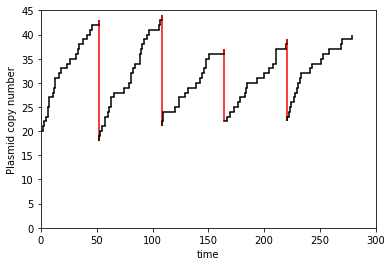

In [14]:
cluster=False
x,t=single_hyperbolic(x0,gen,tau,cluster)
plot_stairs(x,t)

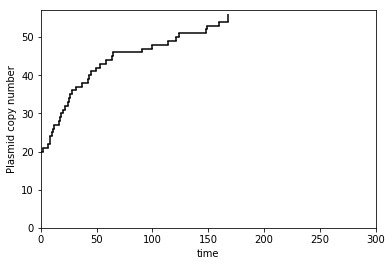

In [15]:
cluster=True
x,t=single_hyperbolic(x0,gen,tau,cluster)
plot_stairs(x,t)

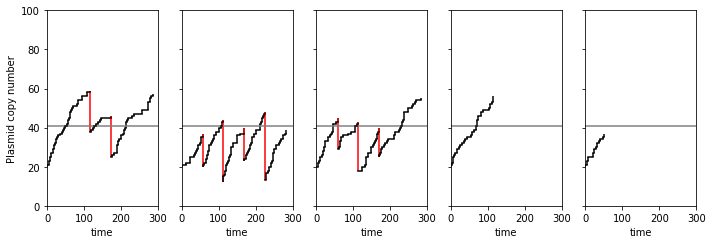

In [18]:
repeats = 5
f,axes = plt.subplots(1,repeats,figsize=(10,3.5))
for i in range(repeats):
    cluster=True
    x,t=single_hyperbolic(x0,gen,tau,cluster)
    plot_stairs_multiple(x,t,i)
axes[0].set_ylabel('Plasmid copy number')    
plt.tight_layout()

# Unclustered fraction

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
def ssa_hyperbolic(x0,tau):
    x=[x0]               #plasmid count count 
    t_x=[0]              #reaction time 
    while t_x[-1]<tau:
        a=(k_tr*x[-1])/(1+K*x[-1]/(s0*n))**n
        epsilon=np.random.uniform(0,1,1)
        t0=(np.log(1/epsilon))/a
        t_x=np.append(t_x,[t_x[-1]+t0])
        x=np.append(x,[x[-1]+1])
    return x[:-1],t_x[:-1]

def find_clustered(x,c_prob):
    k=0
    dummy = np.random.uniform(0,1,x)
    for i in range(x):
        if dummy[i]<=c_prob:
            k+=1
    return k

def single_hyperbolic(x0,gen,tau,cluster,c_prob):
    x=[x0]
    t=np.array([0])
    div_time=np.zeros(gen)
    ratio = np.zeros([gen,2])  #ratio = [inheritance,parent]
    for i in range(gen):
        if x0>0:
            xx,tt=ssa_hyperbolic(x0,tau)
            x=np.append(x,xx)
            t=np.append(t,t[-1]+tt)
            if cluster==False:
                x0=np.random.binomial(xx[-1],0.5)
            else:
                c_num =np.random.choice(np.arange(5),1,p=np.array([.04,.18,.48,.24,.06]))[0]
                if c_num == 0:
                    x0=np.random.binomial(xx[-1],0.5)
                else:
                    c_count = find_clustered(xx[-1],c_prob)
                    #print(c_count/xx[-1])
                    x0=0
                    c_size = np.random.multinomial(c_count, [1/c_num]*c_num, size=1)[0]
                    for k in range(len(c_size)):
                        dummy = np.random.uniform(0,1,1)
                        if dummy<0.5:
                            x0+=c_size[k]
                    for k in range(xx[-1]-c_count):  
                        dummy = np.random.uniform(0,1,1)
                        if dummy<0.5:
                            x0+=1
            #div_time[i]=t[-1]
            #print('############# divide ################')
            ratio[i,:]=[xx[-1],x0/xx[-1]]
    return x,t,ratio

def plot_stairs(x,t):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        plt.plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            plt.vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            plt.vlines(t[i+1],x[i],x[i+1],color='k')
    plt.ylim([0,max(x)+1])
    plt.xlim([0,gen*tau])
    plt.xlabel('time')
    plt.ylabel('Plasmid copy number')
    return None

def plot_stairs_multiple(x,t,k):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        axes[k].plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            axes[k].vlines(t[i+1],x[i],x[i+1],color='k')
    axes[k].set_ylim([0,100])
    axes[k].set_xlim([0,gen*tau])
    axes[k].set_xlabel('time')
    axes[k].hlines(41,0,gen*tau,color='grey')
    if k>0:
        axes[k].set_yticklabels([])
    return None

In [6]:
tau = 60
k_tr = 2.73
K = 9.007936508
s0 = 13.58595
n = 2.5
x0=20

<Figure size 432x288 with 0 Axes>

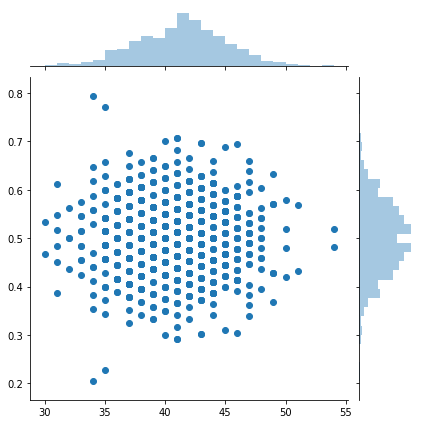

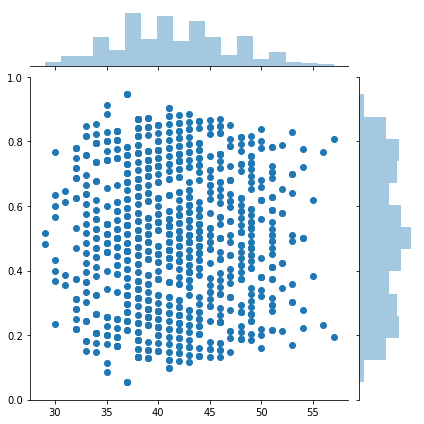

In [7]:
cluster=True
c_prob = [0,0.55]
gen=500
f = plt.figure()
for j in range(2):
    x,t,ratio1=single_hyperbolic(x0,gen,tau,cluster,c_prob[j])
    ratio2 = np.zeros([len(ratio1),2])
    for i in range(len(ratio1)):
        ratio2[i,:]=[ratio1[i,0],1-ratio1[i,1]] 
    ratio = np.append(ratio1,ratio2,axis=0)
    sns.jointplot(ratio[:,0],ratio[:,1])#,x='N_p',y='N_d/N_p')
    if c_prob[j]>0:
        ratio_c = ratio
    else:
        ratio_uc = ratio
#plt.xlabel(r'$N_p$')
#plt.ylabel(r'$N_d/N_p$')

Text(0.5, 1.01, 'Clustering Probb = 0.55')

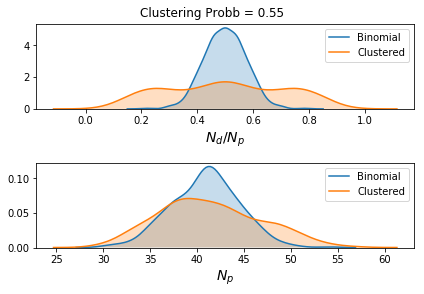

In [8]:
f,axes=plt.subplots(2,1)
sns.kdeplot(ratio_uc[:,1],label='Binomial',shade=True,ax=axes[0])
sns.kdeplot(ratio_c[:,1],label='Clustered',shade=True,ax=axes[0])
axes[0].set_xlabel(r'$N_d/N_p$',fontsize=14)

sns.kdeplot(ratio_uc[:,0],label='Binomial',shade=True,ax=axes[1])
sns.kdeplot(ratio_c[:,0],label='Clustered',shade=True,ax=axes[1])
axes[1].set_xlabel(r'$N_p$',fontsize=14)
plt.tight_layout()
plt.suptitle('Clustering Probb = %1.2f' %(c_prob[1]),y=1.01)


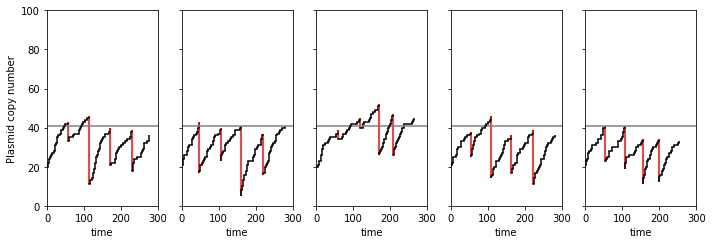

In [202]:
repeats = 5
gen=5
cluster=True
c_prob = 0.6
f,axes = plt.subplots(1,repeats,figsize=(10,3.5))
for i in range(repeats):
    x,t,_=single_hyperbolic(x0,gen,tau,cluster,c_prob)
    plot_stairs_multiple(x,t,i)
axes[0].set_ylabel('Plasmid copy number')    
plt.tight_layout()

In [221]:
ratio

array([[45.        ,  0.62222222],
       [43.        ,  0.74418605],
       [48.        ,  1.        ],
       ...,
       [ 0.        ,  1.        ],
       [ 0.        ,  1.        ],
       [ 0.        ,  1.        ]])